# 02 — CDC Diabetes Health Indicators (UCI dataset 891)

This notebook fetches the CDC survey dataset with the same UCI repository ID used by the source project. Internet access is needed for the initial fetch; the loader caches a local CSV.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
from src.preprocessing import quality_report, descriptive_statistics, candidate_clean
from src.visualization import plot_target, plot_distributions, plot_boxplots, plot_correlations, plot_missingness, plot_target_association
from src.data_loading import load_cdc, find_target
df = load_cdc(cache=True)
target = find_target(df)
print("Shape:", df.shape, "| target:", target, "| duplicate rows:", df.duplicated().sum())
display(df.head())

Fetching CDC Diabetes Health Indicators (UCI dataset 891)...
Shape: (253680, 22) | target: Diabetes_binary | duplicate rows: 24206


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


## Target balance and quality

Verify the target definition from the UCI dataset card. The binary CDC target combines prediabetes and diabetes in its positive class, so it is not equivalent to every other diabetes dataset.

In [2]:
display(df[target].value_counts(dropna=False).rename("count").to_frame())
display((df[target].value_counts(normalize=True, dropna=False)*100).round(2).rename("percent").to_frame())
display(quality_report(df))
display(descriptive_statistics(df))

,count
Diabetes_binary,
0,218334
1,35346


,percent
Diabetes_binary,
0,86.07
1,13.93


,feature,dtype,missing_count,missing_percent,unique_values,minimum,maximum
0,HighBP,int64,0,0.0,2,0,1
1,HighChol,int64,0,0.0,2,0,1
2,CholCheck,int64,0,0.0,2,0,1
3,BMI,int64,0,0.0,84,12,98
4,Smoker,int64,0,0.0,2,0,1
5,Stroke,int64,0,0.0,2,0,1
6,HeartDiseaseorAttack,int64,0,0.0,2,0,1
7,PhysActivity,int64,0,0.0,2,0,1
8,Fruits,int64,0,0.0,2,0,1
9,Veggies,int64,0,0.0,2,0,1


,feature,count,mean,std,min,5%,25%,50%,75%,95%,max,missing,variance,skewness,iqr
0,HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0,0.244960,0.286904,1.0
1,HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0,0.244243,0.307075,1.0
2,CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0,1.0,1.0,0,0.035937,-4.881271,0.0
3,BMI,253680.0,28.382364,6.608694,12.0,20.0,24.0,27.0,31.0,40.0,98.0,0,43.674839,2.122004,7.0
4,Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0,0.246771,0.228810,1.0
5,Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0,0.038925,4.657340,0.0
6,HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0,0.085315,2.778742,0.0
7,PhysActivity,253680.0,0.756544,0.429169,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0,0.184186,-1.195546,0.0
8,Fruits,253680.0,0.634256,0.481639,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0,0.231976,-0.557500,1.0
9,Veggies,253680.0,0.811420,0.391175,0.0,0.0,1.0,1.0,1.0,1.0,1.0,0,0.153018,-1.592239,0.0


## Plots

Many CDC fields are integer-coded indicators, not continuous measurements. The numeric heatmap is exploratory; consider categorical association measures for deeper analysis.

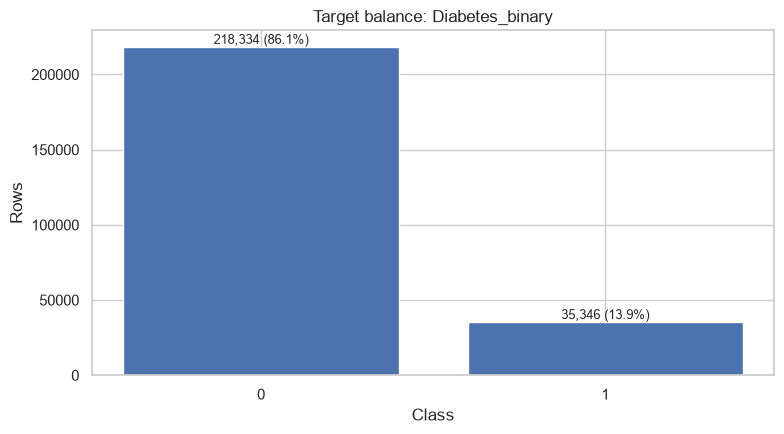

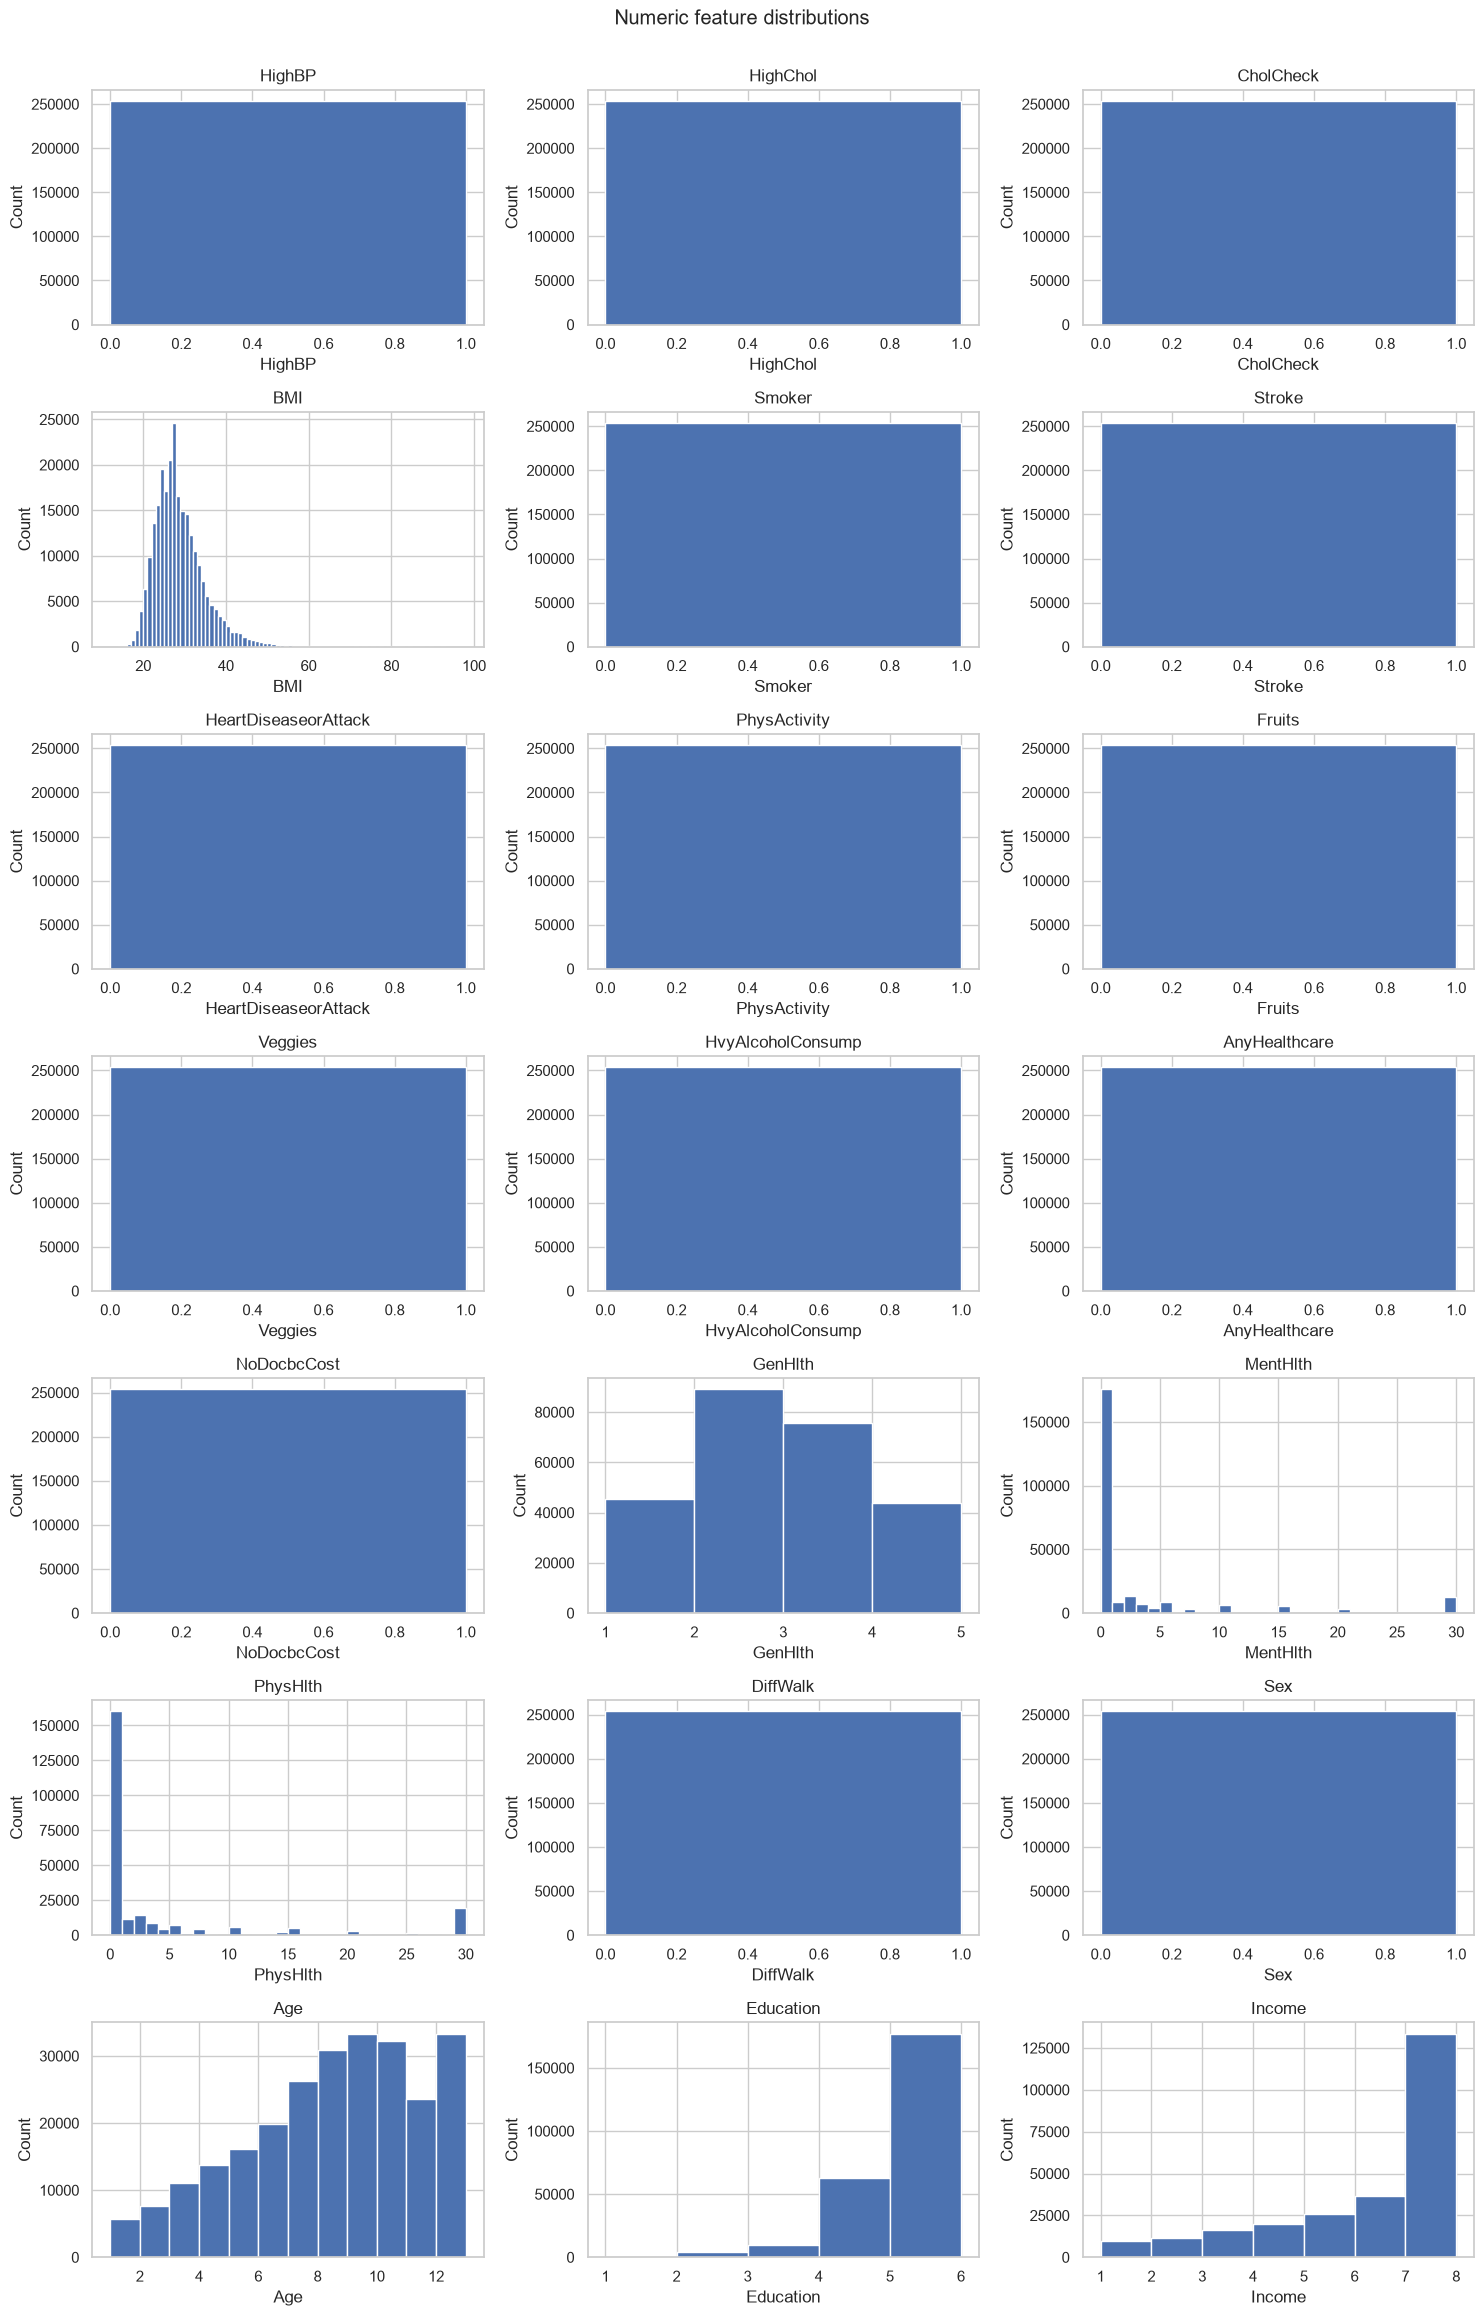

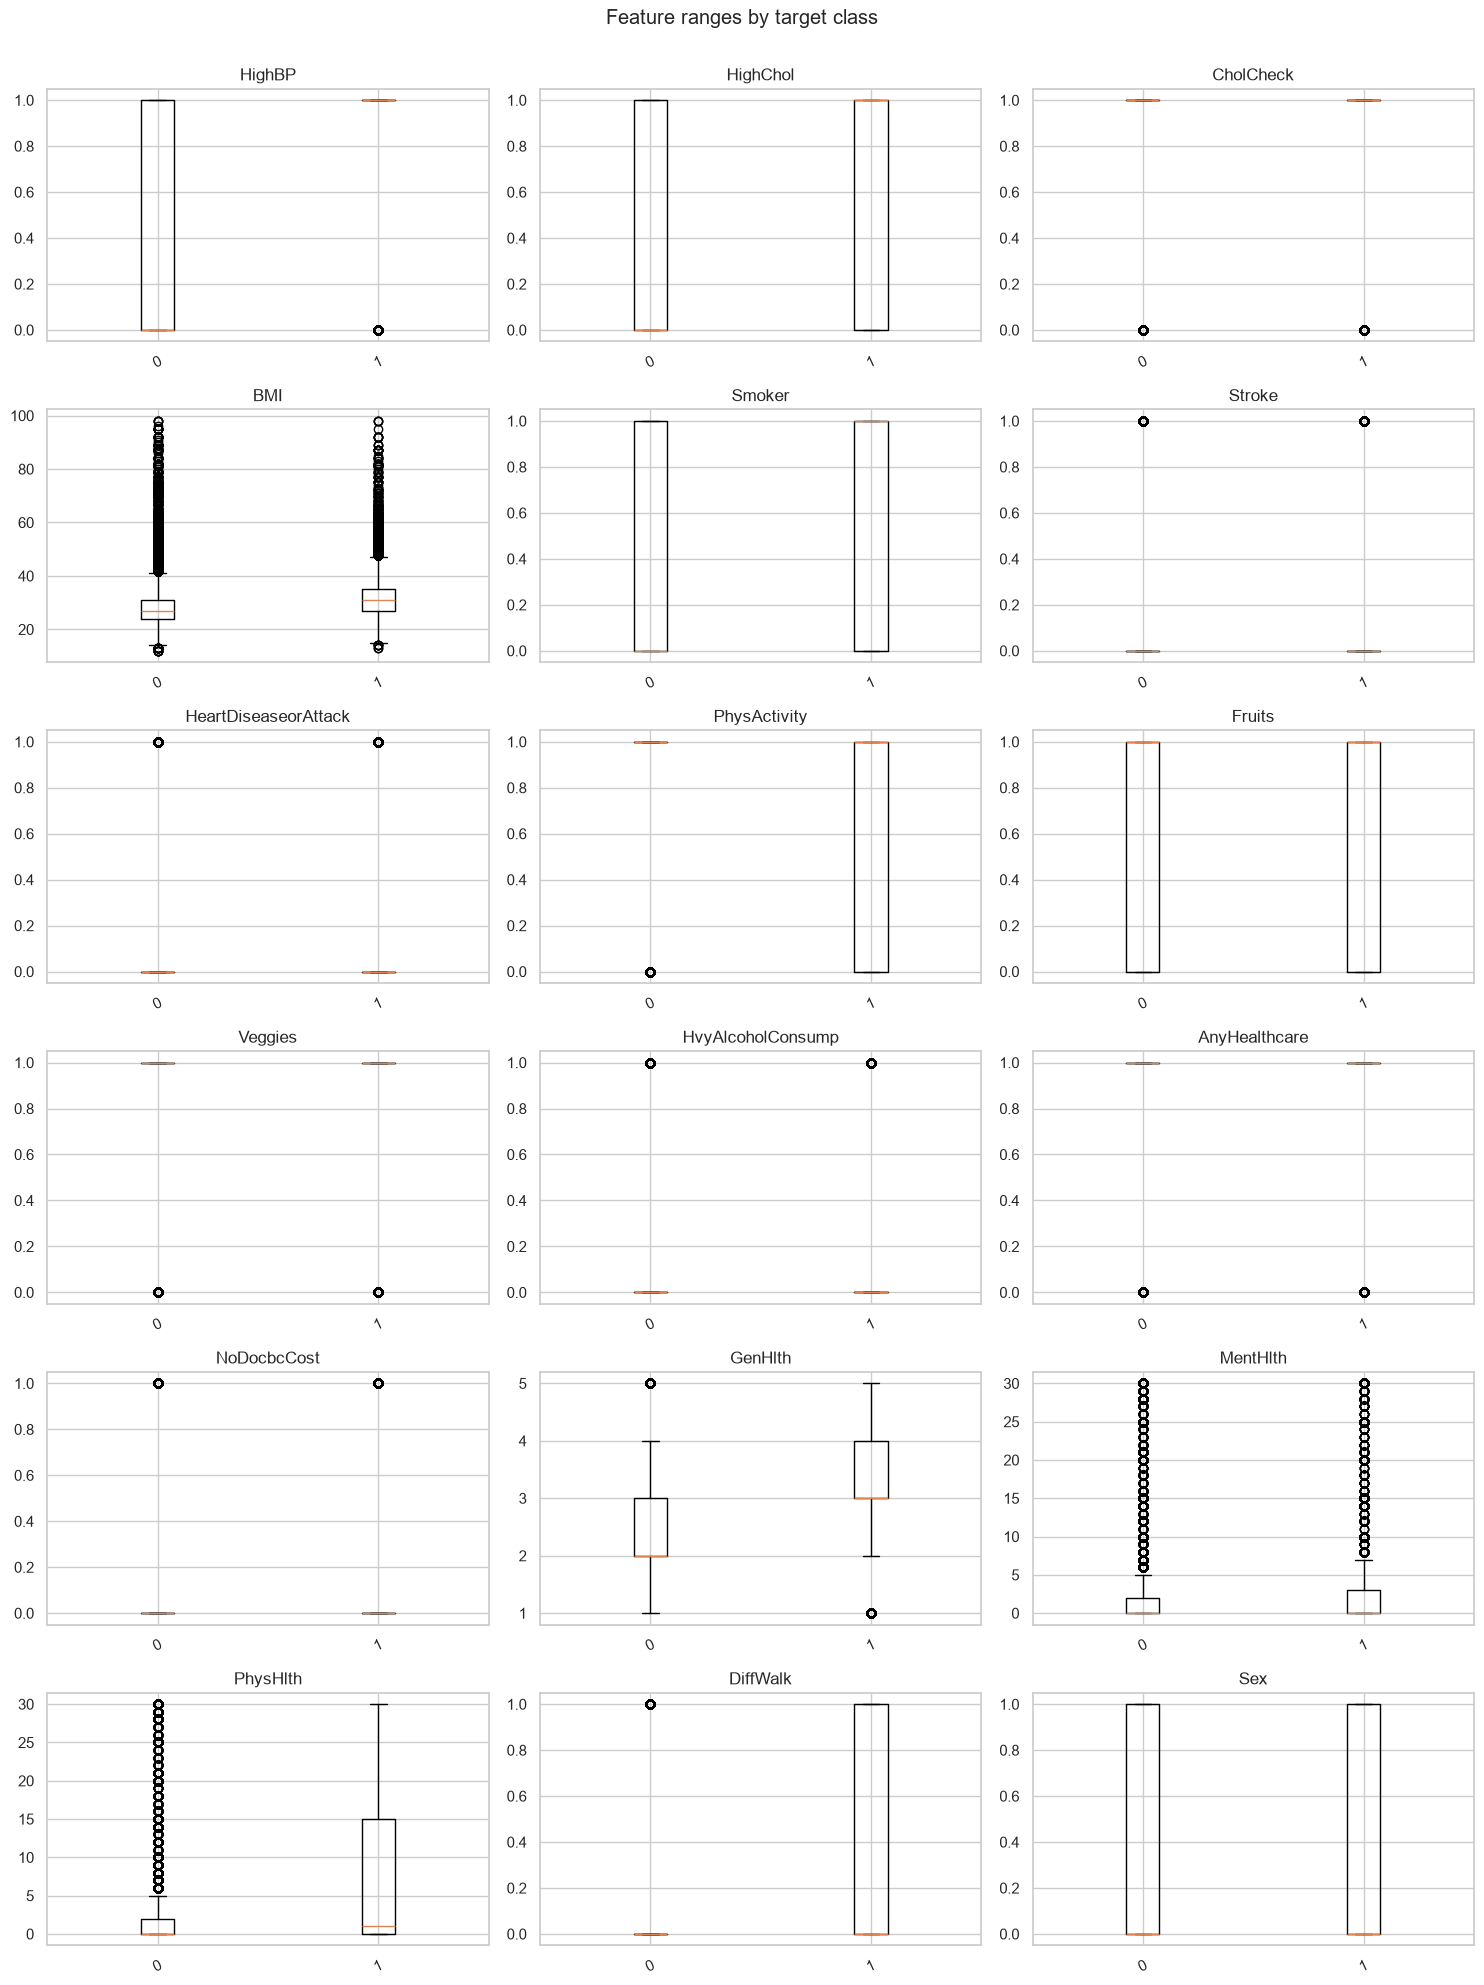

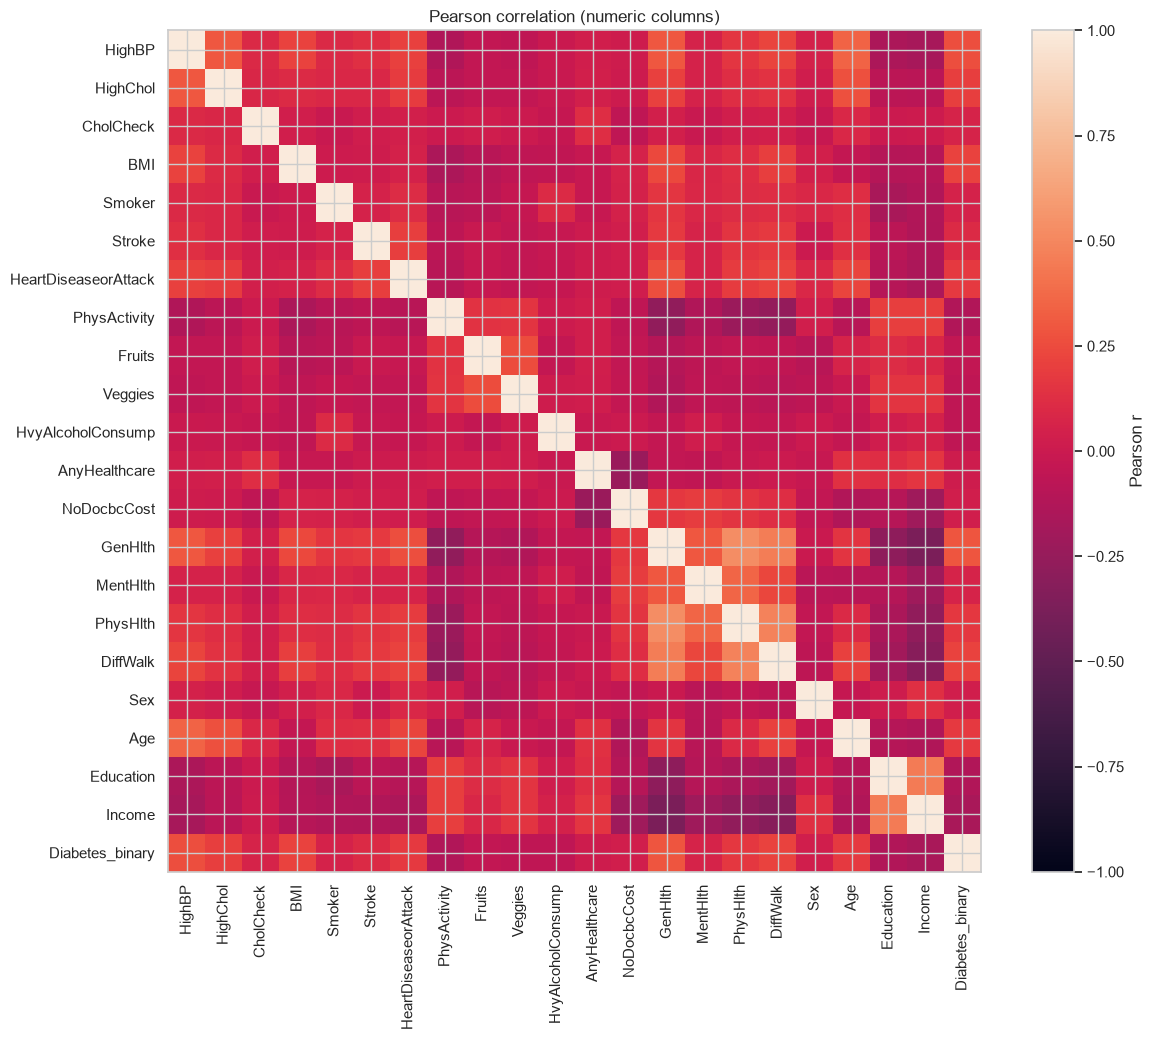

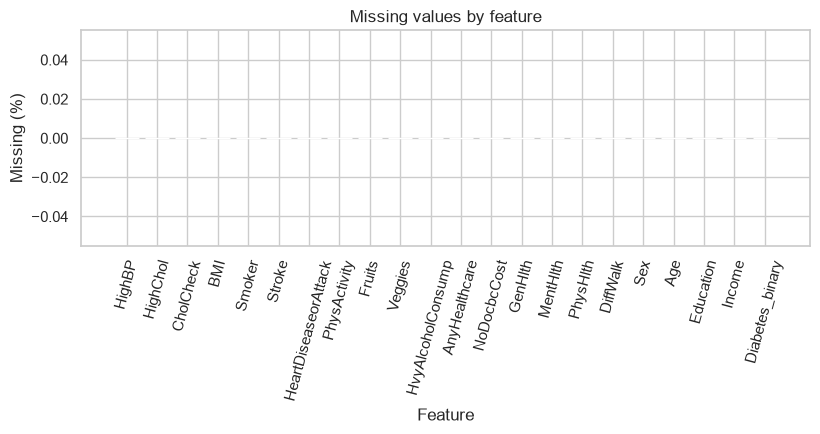

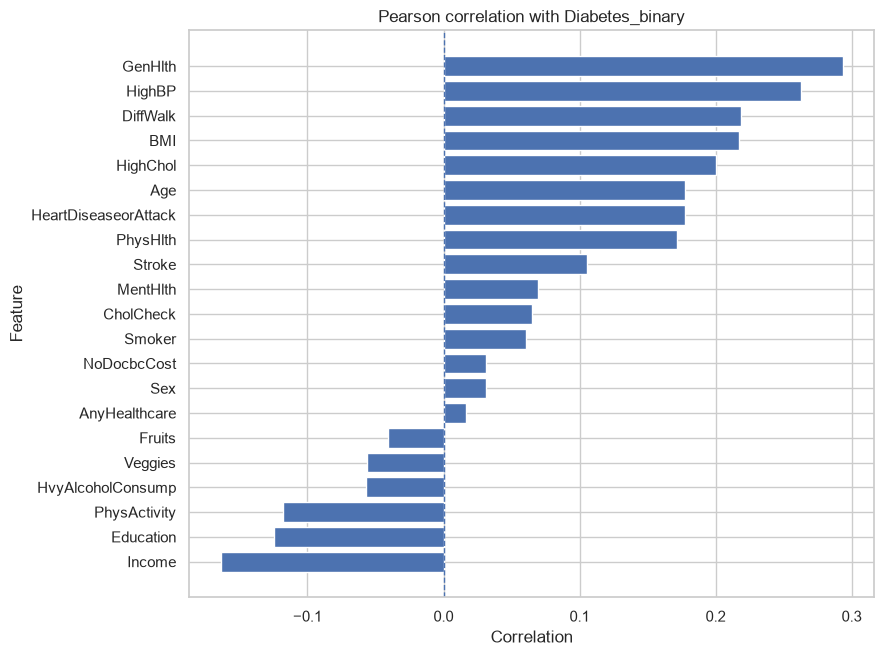

In [3]:
out = ROOT / "outputs" / "figures" / "cdc"
plot_target(df, target, out)
plot_distributions(df, target, out, limit=24)
plot_boxplots(df, target, out, limit=18)
plot_correlations(df, target, out)
plot_missingness(df, out)
plot_target_association(df, target, out)
plt.show()

## Candidate cleaning and reports

Actual NaNs are imputed for a comparison only. Clean-looking values do not prove the dataset is error-free; consult source documentation and validate ranges.

In [ ]:
processed = candidate_clean(df)
print("Missing before:", int(df.isna().sum().sum()), "after:", int(processed.isna().sum().sum()))
report_dir = ROOT / "outputs" / "reports" / "cdc"
report_dir.mkdir(parents=True, exist_ok=True)
quality_report(df).to_csv(report_dir / "data_quality.csv", index=False)
descriptive_statistics(df).to_csv(report_dir / "descriptive_statistics.csv", index=False)

Missing before: 0 after: 0


: 